# Labjournaal BM
## General
**Name:**  Youri Israel en Pim van der Heijden

**Title of the experiment:** Bepaling van de constante van Boltzmann  

**Starting date:**  12/11/2026

**Expected enddate:**  23/11/2026

**Partner:**  Youri Israel/Pim van der Heijden

**Goal of the experiment:** Met de $(I,V)$-karakteristiek van een silicium diode de constante van Boltzmann $k_B$ bepalen.  
**Research question:** Welke waarde van $k_B$ (met onzekerheid) volgt uit de $(I,V)$-karakteristiek van de diode?  
**Expectations or Hypothesis:** De stroom neemt exponentieel toe met de spanning (een rechte lijn in een semi-log plot). Verwacht wordt dat $k_B$ binnen de onzekerheid gelijk is aan de tabelwaarde $1{,}380649\cdot10^{-23}\,\mathrm{J/K}$.  
**Desired accuracy:** Een onzekerheid in $k_B$ van ongeveer 5 %. Die wordt vooral bepaald door de onzekerheid in $n$.

In [29]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from IPython.display import Markdown, display


# Preparation

**Assignments:**

---
### Opdracht 1 – Nauwkeurigheid en gevoeligheid van een DMM

**a) Nauwkeurigheid.** Specificatie ($10\,\mathrm{V}$-bereik): $\pm(0{,}0015\,\%$ van de aflezing $+\ 0{,}0004\,\%$ van het bereik$)$. Aflezing: $5{,}00000\,\mathrm{V}$.

- aflezing: $0{,}0015\,\% \cdot 5{,}00000\,\mathrm{V} = 75\,\mu\mathrm{V}$
- bereik: $0{,}0004\,\% \cdot 10\,\mathrm{V} = 40\,\mu\mathrm{V}$
- totaal: $75 + 40 = 115\,\mu\mathrm{V}$

Resultaat: $U = 5{,}00000 \pm 0{,}00012\,\mathrm{V}$. De laatste twee cijfers op het display zijn dus niet betrouwbaar.

**b) Gevoeligheid.** Een $4\frac{1}{2}$ digit DMM heeft 20000 tellen. Op het $200\,\mathrm{mV}$-bereik is één tel $200\,\mathrm{mV}/20000 = 10\,\mu\mathrm{V}$. De gevoeligheid is dus $10\,\mu\mathrm{V}$. Bij $9\,\mathrm{mV}$ is dat een relatieve resolutie van ca. $0{,}11\,\%$.

---
### Opdracht 2 – Waarom niet direct meten aan de diode?

**Stroom direct meten werkt slecht:**

- De stroom verandert tussen $0{,}1$ en $0{,}6\,\mathrm{V}$ met ca. 5 decades. Je moet steeds van bereik wisselen, en de kleinste stromen (ca. nA) zijn te klein voor een gewone DMM.
- Een stroommeter heeft een eigen weerstand $R_i$ ($100\,\Omega$–$1\,\mathrm{k}\Omega$ in de laagste bereiken). Bij $U_D \approx 0{,}6\,\mathrm{V}$ is de diodeweerstand maar enkele honderden $\Omega$, dus $R_i$ is even groot als $R_D$. De meter verstoort dan de schakeling en de stroom wordt kleiner.

---
### Opdracht 3 – Spanningsdeler $330\,\Omega$ en $1000\,\Omega$, $P_{max} = 1\,\mathrm{W}$

- Maximale stroom uit $P = I^2R$: $I_{max} = \sqrt{P/R}$
  - $330\,\Omega$: $\sqrt{1/330} = 55{,}0\,\mathrm{mA}$
  - $1000\,\Omega$: $\sqrt{1/1000} = 31{,}6\,\mathrm{mA}$
- In serie loopt door beide dezelfde stroom, dus de kleinste limiet telt: $I = 31{,}6\,\mathrm{mA}$. Dan is $U_{max} = 0{,}0316 \cdot 1330 \approx 42\,\mathrm{V}$.
- Bij $20\,\mathrm{V}$: $I = 20/1330 = 15{,}04\,\mathrm{mA}$
  - $U_{330} = 15{,}04\,\mathrm{mA} \cdot 330\,\Omega = 4{,}96\,\mathrm{V}$
  - $U_{1000} = 15{,}04\,\mathrm{mA} \cdot 1000\,\Omega = 15{,}04\,\mathrm{V}$ (som $= 20{,}00\,\mathrm{V}$, klopt)

---
### Opdracht 4 – Basisopstelling (diode en $R_1$ in serie, twee spanningsmeters)

- **Spanning over de diode:** de ene voltmeter meet de bronspanning $U_{bron}$, de andere de spanning over $R_1$. Dus $U_D = U_{bron} - U_{R_1}$.
- **Stroom door de diode:** $R_1$ staat in serie met de diode, dus $I_D = U_{R_1}/R_1$. De stroom volgt dus uit een spanningsmeting, zonder stroommeter.
- **Onzekerheden:**

$$u(U_D) = \sqrt{u(U_{bron})^2 + u(U_{R_1})^2} \qquad
{u(I_D)}= {I_D}\sqrt{\left(\frac{u(U_{R_1})}{U_{R_1}}\right)^2 + \left(\frac{u(R_1)}{R_1}\right)^2}$$


---
### Opdracht 5 – Tweede spanningsdeler ($R_2$, $R_3$)


- **Afleiding.** Parallel: $R_p = \dfrac{R_3 (R_1 + R_D)}{R_3 + R_1 + R_D}$. Met $R_2$ als deler geeft dat
$$U = \frac{R_p}{R_2 + R_p}\, U_{bron}.$$
  Als $R_3 \ll R_1 + R_D$, dan is $R_p \approx R_3$ en dus
$$U = \frac{R_3}{R_2 + R_3}\, U_{bron}.$$
- **Voorwaarde $R_3 \ll R_1 + R_D$.** Dan is de stroom door de diodetak veel kleiner dan die door $R_3$, en belast de diodetak de deler niet.
- **Extra stap voor $U_D$.** $U$ staat over $R_1$ én de diode samen, dus
$$U_D = U - U_{R_1} = \frac{R_3}{R_2 + R_3}\, U_{bron} - U_{R_1}.$$

---
### Opdracht 6 – Python-script en onzekerheid in $k_B$

Het script staat in de code-cellen hieronder.

$$u(k_B) = |k_B|\sqrt{\left(\frac{u(b)}{b}\right)^2 + \left(\frac{u(n)}{n}\right)^2 + \left(\frac{u(T)}{T}\right)^2}.$$

**Method:** Diode en $R_1$ in serie, met twee spanningsmeters. Een tweede spanningsdeler ($R_2$, $R_3$) maakt een stabiele lage spanning. 

**Theory:** $I_D(U_D) = I_0\left(e^{\,b\,U_D} - 1\right)$ met $b = -\dfrac{q}{n k_B T}$, dus $k_B = -\dfrac{q}{b\,n\,T}$. Hier is $q = -1{,}602\cdot10^{-19}\,\mathrm{C}$ (lading van het elektron), zodat $b > 0$.  
**Independent variable:** $U_{bron}$ (en daarmee $U_D$)  
**Dependent variable:** $I_D$  
**Controlled variables:** temperatuur $T$, weerstanden $R_1$, $R_2$, $R_3$, DMM-bereiken  
**Measurement instruments & Settings:** 3½ digit DMM (bronspanning), 5½ digit DMM (spanning over $R_1$ en de weerstandsmetingen)  
**Procedure:**
1. Meet $R_1$, $R_2$ en $R_3$ met de 5½ digit DMM.
2. Bouw de schakeling op: bron → $R_2$, met $R_3$ parallel aan ($R_1$ + diode).
3. Verhoog $U_{bron}$ stapsgewijs. Noteer bij elke stap $U_{bron}$, $U_{R_1}$ en de ingestelde meetbereiken.

**Setup (drawing or picture):**
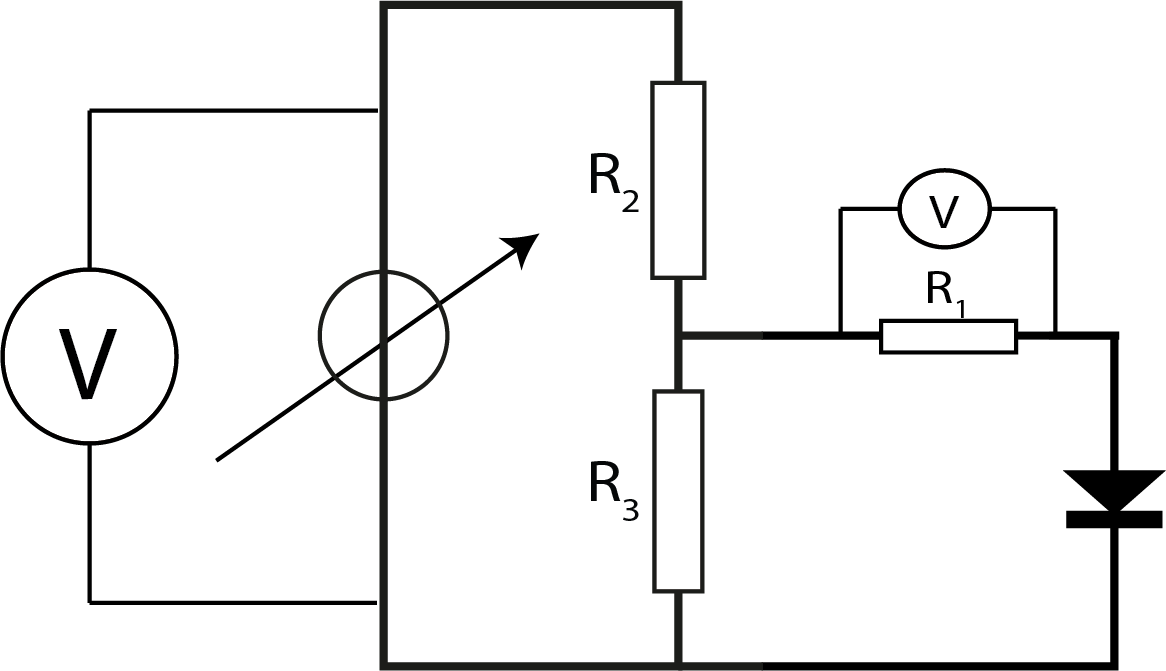
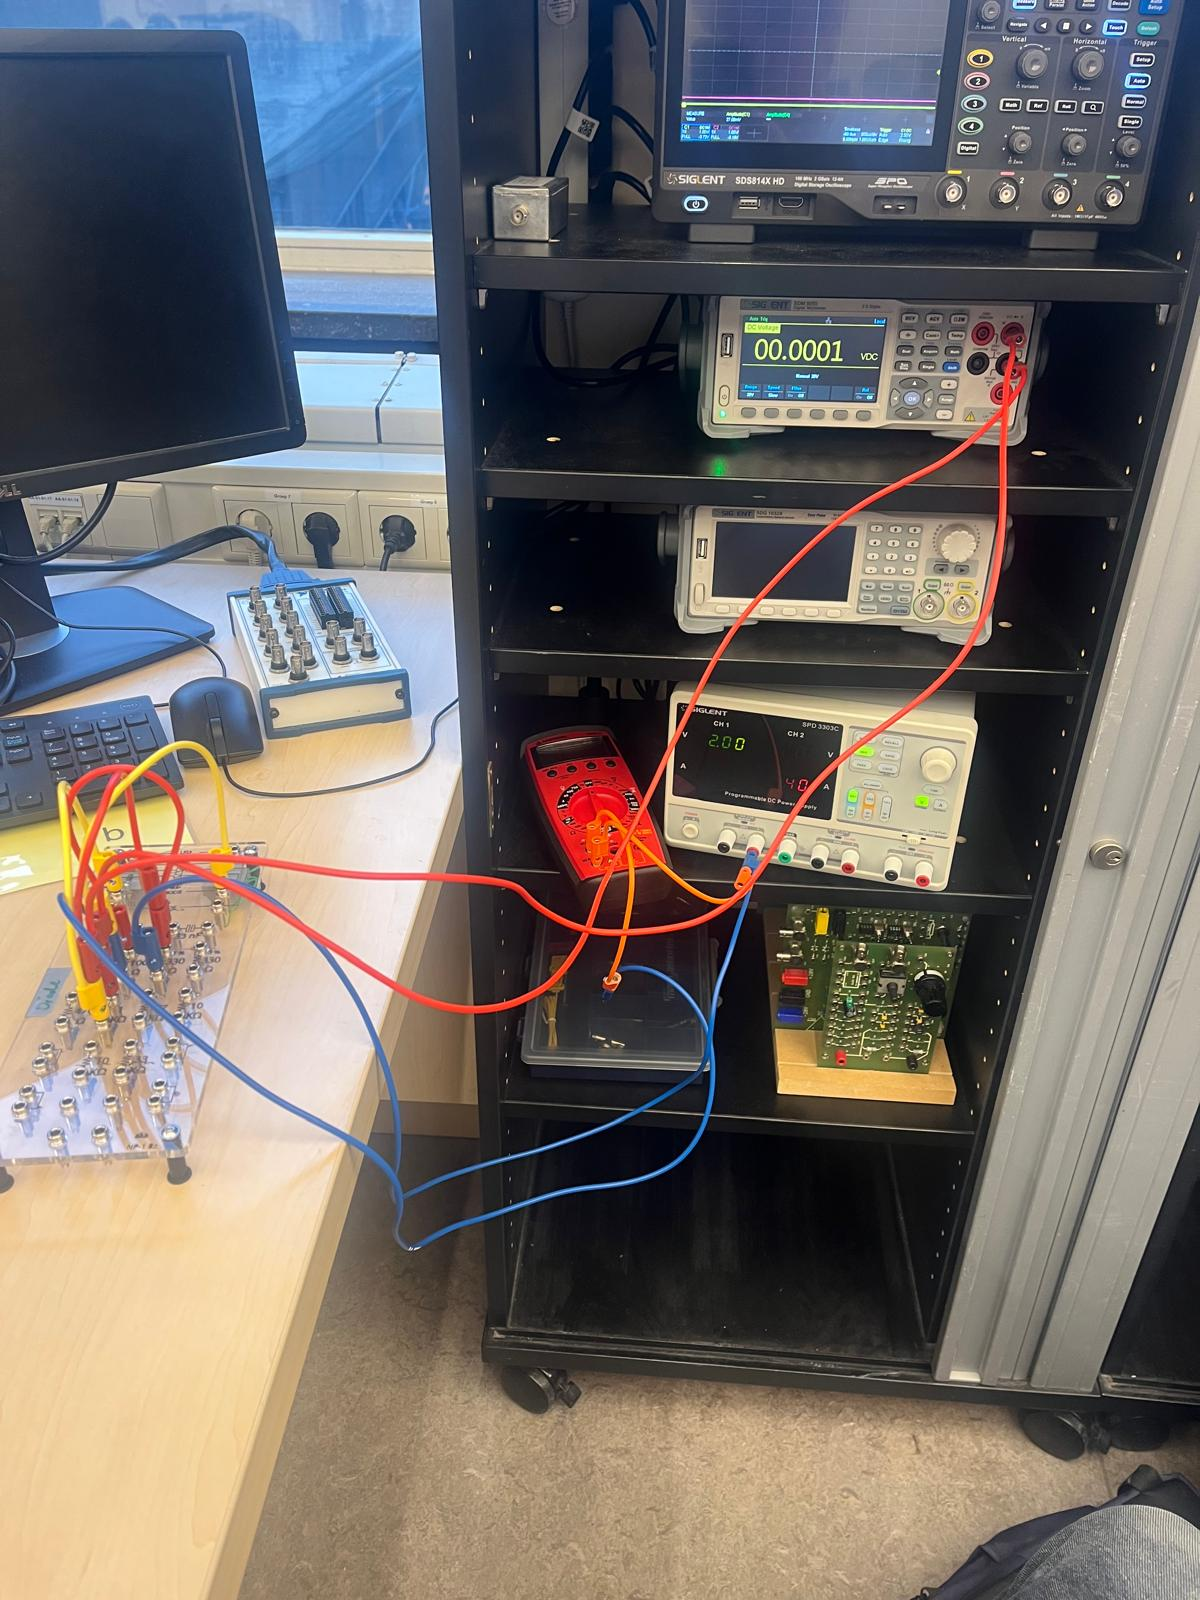
**Notes:**  
**About accuracy:** De onzekerheid van elke spanning komt uit de DMM-specificatie (% van aflezing + % van bereik + tellen). Die van $R_1$, $R_2$, $R_3$ komt uit de weerstandsmetingen.

In [30]:
# DMM-specificatie als (% van aflezing, % van bereik, aantal tellen, tellen op het volle bereik)
#Deze code is achteraf geschreven, we hadden geen toegang meer tot de meters en wisten niet de specificaties, dus hebben een schatting gemaakt zodat we wel de berekeningen konden uitvoeren

SPEC_35 = (0.7,  0.0,   1, 4000)     # 3 3/4 digit
SPEC_55 = (0.015, 0.003, 0, 200000) # Siglent SDM3055, 5 1/2 digit

def u_dmm(aflezing, bereik, spec):
    # Onzekerheid van een DMM-meting   
    pct_aflezing, pct_bereik, tellen, max_tellen = spec
    een_tel = bereik / max_tellen
   
    return pct_aflezing/100*aflezing + pct_bereik/100*bereik + tellen*een_tel

def lijn(U, b, lnI0):
    # ln(I_D) = b*U_D + ln(I0), zie vergelijking (4)
    return b*U + lnI0

# Execution

In [45]:
#ruwe data
U_bron   = np.array([2.634,2.794,2.943,3.093,3.243,3.393,3.542,3.692,3.843, 3.992,4.14,4.29,4.44,4.59,4.74,4.89,5.04,5.19,5.33])
rang_bron = np.array([4,4,4,4,4,4,4,4,4,4,4,40,40,40,40,40,40,40,40])
U_R1     = np.array([0.09961, 0.12464,0.14927, 0.17499,0.20144,0.22858,0.25610,0.28412, 0.31259,0.34139,0.37033,0.39955,0.42912,0.45863,0.48854,0.518460,0.54860,0.57874,0.60911])
rang_R1   = np.array([2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2])

# Weerstanden uit de weerstandsmetingen
R1, u_R1 = 997.3,   0.46  # 2 kOhm-bereik: 0.020% van 997.3 + 0.003% van 2000 + 0.2 Ohm (draden) = 0.4595 Ohm
R2, u_R2 = 328.72,  0.33  # 2 kOhm-bereik: 0.020% van 328.72 + 0.003% van 2000 + 0.2 Ohm (draden) = 0.3257 Ohm
R3, u_R3 = 100.079, 0.24  # 200 Ohm-bereik: 0.030% van 100.079 + 0.005% van 200 + 0.2 Ohm (draden) = 0.2400 Ohm

q = -1.602176634e-19       # lading elektron [C]
T, u_T = 293.15, 1.0       # temperatuur [K],
n, u_n = 2.0, 0.1          # idealiteitsfactor Si (uit de opdrachttekst)

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**  
Uit $U_{bron}$ en $U_{R_1}$ worden $U_D$ en $I_D$ uitgerekend (opdracht 4 en 5), inclusief onzekerheden. **In de semi-log plot liggen de meetpunten (van $U_D \approx 0{,}51$ tot $0{,}64\,\mathrm{V}$) bijna op een rechte lijn. Dat komt doordat de exponent in dit gebied groot is: met $b \approx 15\,\mathrm{V^{-1}}$ geldt $e^{bU_D}  \approx 3000 \gg 1$. De $-1$ in de diodevergelijking mag je dan weglaten:

$$I_D = I_0\, e^{bU_D}, \qquad b = \frac{-q}{n k_B T} \tag{3}$$

Neem je van beide kanten de natuurlijke logaritme, dan krijg je

$$\ln I_D = b\,U_D + \ln I_0 \tag{4}$$

Dit is een rechte lijn $y = c\,x + d$, met helling $c = b$ en snijpunt $d = \ln I_0$. Uit de helling volgt

$$k_B = \frac{-q}{b\,n\,T}$$

**Onzekerheid in $\ln I_D$.** Voor de fit moeten de onzekerheden ook naar $\ln I_D$ worden omgerekend:

- uit $I_D$: $u(\ln I_D) = u(I_D)/I_D$
- uit $U_D$: een fout $u(U_D)$ verschuift het punt langs de lijn, wat overeenkomt met $b\,u(U_D)$ in $\ln I_D$

Samen geeft dat $u_{tot} = \sqrt{\left(u(I_D)/I_D\right)^2 + \left(b\,u(U_D)\right)^2}$.

In [46]:
# Bewerkte data en onzekerheden
u_Ubron = u_dmm(U_bron, rang_bron, SPEC_35)
u_UR1   = u_dmm(U_R1,   rang_R1,   SPEC_55)

deler = R3/(R2+R3)
U_diodetak = U_bron*deler            # spanning over R1 + diode
U_D = U_diodetak - U_R1              # spanning over de diode
I_D = U_R1/R1                        # stroom door de diode

# onzekerheden (kwadratisch optellen)
u_Udiodetak = np.sqrt((deler*u_Ubron)**2 + (U_bron*R2/(R2+R3)**2*u_R3)**2 + (U_bron*R3/(R2+R3)**2*u_R2)**2)

u_UD = np.sqrt(u_Udiodetak**2 + u_UR1**2)

u_ID = I_D*np.sqrt((u_UR1/U_R1)**2 + (u_R1/R1)**2)


for i in range(len(U_D)):
    print(f"U_D = {U_D[i]:.4f} ± {u_UD[i]:.4f} V    I_D = {I_D[i]:.3e} ± {u_ID[i]:.1e} A")

U_D = 0.5151 ± 0.0040 V    I_D = 9.988e-05 ± 8.8e-08 A
U_D = 0.5275 ± 0.0042 V    I_D = 1.250e-04 ± 9.8e-08 A
U_D = 0.5376 ± 0.0044 V    I_D = 1.497e-04 ± 1.1e-07 A
U_D = 0.5469 ± 0.0045 V    I_D = 1.755e-04 ± 1.2e-07 A
U_D = 0.5555 ± 0.0047 V    I_D = 2.020e-04 ± 1.3e-07 A
U_D = 0.5633 ± 0.0049 V    I_D = 2.292e-04 ± 1.4e-07 A
U_D = 0.5706 ± 0.0051 V    I_D = 2.568e-04 ± 1.5e-07 A
U_D = 0.5776 ± 0.0053 V    I_D = 2.849e-04 ± 1.7e-07 A
U_D = 0.5843 ± 0.0055 V    I_D = 3.134e-04 ± 1.8e-07 A
U_D = 0.5903 ± 0.0057 V    I_D = 3.423e-04 ± 1.9e-07 A
U_D = 0.5959 ± 0.0059 V    I_D = 3.713e-04 ± 2.1e-07 A
U_D = 0.6017 ± 0.0122 V    I_D = 4.006e-04 ± 2.2e-07 A
U_D = 0.6071 ± 0.0124 V    I_D = 4.303e-04 ± 2.3e-07 A
U_D = 0.6126 ± 0.0125 V    I_D = 4.599e-04 ± 2.5e-07 A
U_D = 0.6177 ± 0.0127 V    I_D = 4.899e-04 ± 2.6e-07 A
U_D = 0.6228 ± 0.0129 V    I_D = 5.199e-04 ± 2.8e-07 A
U_D = 0.6277 ± 0.0131 V    I_D = 5.501e-04 ± 2.9e-07 A
U_D = 0.6326 ± 0.0133 V    I_D = 5.803e-04 ± 3.1e-07 A
U_D = 0.63

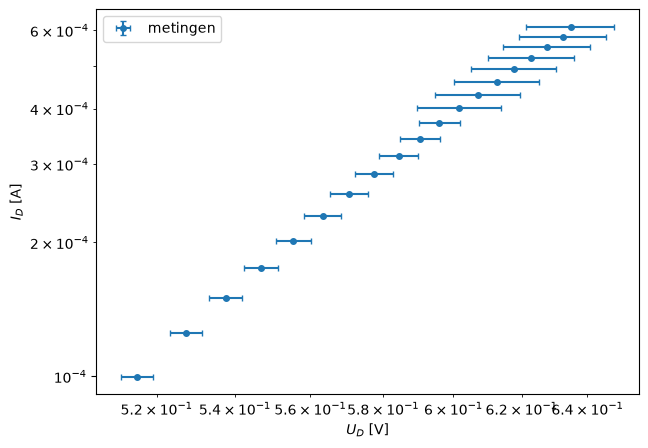

In [47]:
plt.figure(figsize=(7, 5))
plt.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt='o', ms=4, capsize=2, label='metingen')
plt.loglog()
plt.xlabel('$U_D$ [V]')
plt.ylabel('$I_D$ [A]')
plt.legend()
plt.show()



b        = 15.60 ± 0.64 1/V
I0       = 3.40e-08 A
chi^2    = 2.90 (dof = 17)
chi^2_red = 0.17


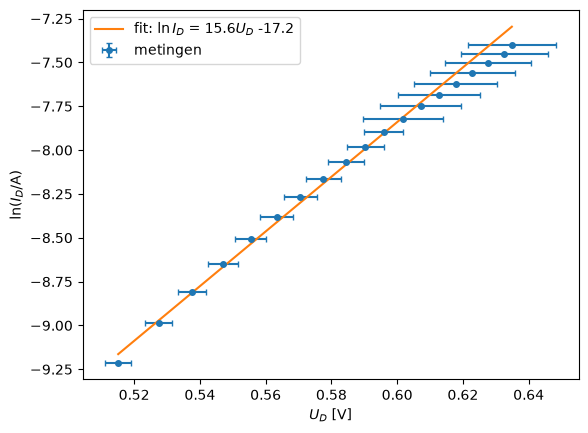

In [51]:
# Fit van een rechte lijn: ln(I_D) = b*U_D + ln(I0)
x = U_D
y = np.log(I_D)

# Stap 1: eerste schatting van b, alleen met de onzekerheid in I_D
u_y = u_ID / I_D
(b, lnI0), cov = curve_fit(lijn, x, y, sigma=u_y, absolute_sigma=True)

# Stap 2: onzekerheid in U_D erbij (die hangt van b af) en opnieuw fitten
u_y = np.sqrt((u_ID/I_D)**2 + (b*u_UD)**2)
(b, lnI0), cov = curve_fit(lijn, x, y, p0=[b, lnI0], sigma=u_y, absolute_sigma=True)
u_b, u_lnI0 = np.sqrt(np.diag(cov))

# Bereken chi^2 en gereduceerde chi^2
residuen = y - lijnsz(x, b, lnI0)
chi2 = np.sum((residuen / u_y)**2)
dof = len(x) - 2  # aantal vrijheidsgraden (N meetpunten - 2 fitparameters)
chi2_red = chi2 / dof

print(f"b        = {b:.2f} ± {u_b:.2f} 1/V")
print(f"I0       = {np.exp(lnI0):.2e} A")
print(f"chi^2    = {chi2:.2f} (dof = {dof})")
print(f"chi^2_red = {chi2_red:.2f}")

# Plot: ln(I_D) tegen U_D met de gefitte rechte lijn
xx = np.linspace(x.min(), x.max(), 1000)
plt.figure()
plt.errorbar(x, y, xerr=u_UD, yerr=u_ID/I_D, fmt='o', ms=4, capsize=2, label='metingen')
plt.plot(xx, lijn(xx, b, lnI0), label=f'fit: $\\ln I_D$ = {b:.1f}$U_D$ {lnI0:+.1f}')
plt.xlabel('$U_D$ [V]')
plt.ylabel('$\\ln(I_D / \\mathrm{A})$')
plt.legend()
plt.show()


**Describing the pattern in the processed data:**  
In de semi-log plot liggen de punten op een rechte lijn. De stroom $I_D$ neemt dus exponentieel toe met $U_D$, zoals de diodevergelijking voorspelt. Over het gebruikte meetgebied verandert $I_D$ met enkele decades.

In [49]:
# Eindresultaat: k_B met onzekerheid
kB = -q/(b*n*T)
u_kB = abs(kB)*np.sqrt((u_b/b)**2 + (u_n/n)**2 + (u_T/T)**2)
kB_tabel = 1.380649e-23
verschil = abs(kB - kB_tabel)/u_kB

print(f"k_B = ({kB:.3e} ± {u_kB:.1e}) J/K")
print(f"tabelwaarde = {kB_tabel:.6e} J/K, verschil = {verschil:.1f} x onzekerheid")

k_B = (1.749e-23 ± 1.1e-24) J/K
tabelwaarde = 1.380649e-23 J/K, verschil = 3.3 x onzekerheid


**Notes:**  

# Discussion

**Resultaat.** We vinden $k_B = (1{,}7 \pm 0{,}1)\cdot10^{-23}\,\mathrm{J/K}$. Dat is 27 % hoger dan de tabelwaarde en wijkt 3,3 keer de onzekerheid af. Er zit dus een systematische fout in de meting of de verwerking. Wel klopt het verwachte patroon: in de semi-log plot liggen de punten op een rechte lijn, dus $I_D$ groeit exponentieel met $U_D$.

**Belangrijkste oorzaak: de deler $R_2$/$R_3$ wordt belast.** In opdracht 5 hebben we aangenomen dat $R_3 \ll R_1 + R_D$. Dat klopt hier niet goed genoeg. $R_1 + R_D$ loopt van ongeveer $6{,}2\,\mathrm{k\Omega}$ tot $2{,}0\,\mathrm{k\Omega}$. Dat is maar 20 tot 60 keer zo groot als $R_3 = 100\,\Omega$. Daardoor is de echte spanning over de diodetak lager dan $\frac{R_3}{R_2+R_3}U_{bron}$. Daardoor wordt de $U_D$-as uitgerekt en komt de helling $b$ te laag uit, zodat $k_B$ te hoog uitkomt. 


# Conclusion

Uit de $(I,V)$-karakteristiek van de siliciumdiode volgt $k_B = (1{,}7 \pm 0{,}1)\cdot10^{-23}\,\mathrm{J/K}$. De stroom neemt zoals verwacht exponentieel toe met de spanning. Toch wijkt $k_B$ 3,3 keer de onzekerheid af van de tabelwaarde $1{,}380649\cdot10^{-23}\,\mathrm{J/K}$, dus de hypothese wordt niet bevestigd. De gewenste nauwkeurigheid van 5 % hebben we niet gehaald, vooral door de onzekerheid in de idealiteitsfactor $n$.

**Verbeteringen:**
- **Betere weerstanden kiezen.** $R_3$ moet veel kleiner zijn dan $R_1 + R_D$, minstens een factor 1000 in plaats van 20 tot 60. Dat kan met een kleinere $R_3$ en $R_2$, zoals $10\,\Omega$ en $33\,\Omega$ (let dan wel op het vermogen), of met een grotere $R_1$, zoals $10$ tot $100\,\mathrm{k\Omega}$. Een grotere $R_1$ maakt de diodestroom kleiner. Dan meet je ook kleinere stromen, dus over meer decades.
- Bepaal $n$ voor deze diode apart (of zoek die op in de datasheet), en meet de temperatuur.
- Noteer tijdens de meting de echte DMM-specificaties.

# Additional notes, remarks, explanations, thoughts etc